# Working with the review's literature data: growth, breadth, parameters and tests

A review makes claims about a literature: how fast a model spread, which communities use it, what parameter values are reported for which materials, and which kinds of experiment it passes. Each such claim rests on a small data set that you can inspect yourself. This notebook loads the three literature data sets behind Secs. III and IX of the review with **pandas**, recomputes the numbers quoted in the text (the doubling time of publications, the field composition compared with the Bingham and Casson models, the ranges of $\sigma_y$ and $n$), reproduces Figs. 2, 3 and 13, and tabulates which kinds of test the Herschel–Bulkley (HB) model passes. Along the way it shows why two materials with the same flow index need not share a mechanism.

### Where this is in the review
- **Sec. III A** (spread of the model across disciplines) with **Fig. 2(a,b)**; **Sec. III B** (one model for many materials) with **Fig. 2(c)**, **Table I** and **Fig. 3**; **Sec. III D** and **Table III** (what the community built).
- **Sec. V A–C** (classes of yield-stress materials; predicted and fitted exponents, **Table VI**, **Eq. (14)**) and **Sec. VI D** (dependence of fitted parameters on the rate window).
- **Sec. IX** (predictive capability: testing the model beyond the rheometer), **Table XII** and **Fig. 13**; **Sec. IX H** (what the experiments show); **Table XI** (coordinates of applicability).
- Data: `data/hb_bibliometrics.json` (OpenAlex counts, queried 25 October 2026), `data/hb_parameter_atlas.csv`, `data/figure_data/fig13_transfer_matrix.csv`; scripts `scripts/fig02_usage.py`, `fig03_parameter_atlas.py`, `fig13_transfer_matrix.py`, and the checks in `scripts/verify_numbers.py`.

### Learning objectives
After working through this notebook you should be able to
1. load nested JSON and CSV literature data into tidy pandas tables;
2. estimate a doubling time from a log-linear fit and judge how much it depends on the fitting window and on database coverage;
3. compare the field composition of works naming the HB, Bingham and Casson models;
4. summarize reported HB parameters by material class and explain why a shared $n$ does not imply a shared mechanism;
5. tabulate the outcomes of the experimental tests of Table XII by kind of change between calibration and test.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook runs from notebooks/ or from the root
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
DATA = ROOT / "data"
FIGDATA = DATA / "figure_data"
sys.path.insert(0, str(ROOT / "scripts"))

import hbstyle as hs   # house style, palette C and HB helper functions (we never call hs.save)
C = hs.C
plt.rcParams["figure.dpi"] = 110
print("data folder found:", (ROOT / "data").is_dir())

data folder found: True


## 1. The bibliometric record (Sec. III A)

`hb_bibliometrics.json` stores counts from the OpenAlex database (Priem et al. 2022), queried in October 2026: works per year whose title or abstract, or whose full text, mentions "Herschel-Bulkley"; works grouped by OpenAlex's automatically assigned primary topic; citations of the 1926 Kolloid-Zeitschrift paper; and a comparison with the Bingham and Casson models by research field. The query strings and caveats are stored with the counts.

In [2]:
B = json.loads((DATA / "hb_bibliometrics.json").read_text())
print("source :", B["source"])
print("notes  :", B["notes"])
for k, q in B["queries"].items():
    print(f"query ({k}): {q}")
print(f"\ntotals: {B['title_abstract_total']} works (title or abstract), {B['fulltext_total']} (full text); "
      f"1926 paper cited {B['hb1926_citations_total']} times")

source : OpenAlex API (https://api.openalex.org), queried 2026-10-25
notes  : Entries dated 1830 and 1832 are misdated records and are excluded. 2026 is a partial year. Topic labels are OpenAlex's automatic classification. Full-text coverage is incomplete and uneven before about 2000.
query (title_abstract): works?filter=title_and_abstract.search:"Herschel-Bulkley"&group_by=publication_year
query (fulltext): works?filter=fulltext.search:"Herschel-Bulkley"&group_by=publication_year
query (topics): works?filter=title_and_abstract.search:"Herschel-Bulkley"&group_by=primary_topic.id
query (hb1926_citations): works/doi:10.1007/BF01432034

totals: 4883 works (title or abstract), 12300 (full text); 1926 paper cited 1513 times


In [3]:
# Tidy table: one row per year, one column per kind of count
ta = pd.DataFrame(B["title_abstract_by_year"], columns=["year", "title_or_abstract"]).set_index("year")
ft = pd.DataFrame(B["fulltext_by_year"], columns=["year", "full_text"]).set_index("year")
cites = pd.DataFrame(B["hb1926_citations_by_year"], columns=["year", "citations_1926_paper"]).set_index("year")
years = ta.join(ft, how="outer").join(cites, how="outer").fillna(0).astype(int)
years.tail(8)

,title_or_abstract,full_text,citations_1926_paper
year,,,
2019,235,700,91
2020,235,719,101
2021,255,842,133
2022,258,863,142
2023,274,982,120
2024,283,966,123
2025,329,1034,113
2026,392,1025,104


**Doubling time.** If a count grows exponentially, $N(t) = N_0\,e^{rt}$, then $\ln N$ is linear in $t$ with slope $r$, and the count doubles every $t_2 = \ln2/r$ years. The review fits the full-text counts from 1995 to 2025 (2026 is a partial year and is excluded) and finds about 5.5 years. It also states that 97% of the full-text mentions appeared since 2000 and that the model has been mentioned in about 1000 works a year since 2023.

In [4]:
def doubling_time(series, first, last):
    s = series.loc[first:last]
    s = s[s > 0]
    slope = np.polyfit(s.index.values, np.log(s.values), 1)[0]
    return np.log(2) / slope

t2 = doubling_time(years.full_text, 1995, 2025)
share_since_2000 = 100 * years.full_text.loc[2000:].sum() / years.full_text.sum()
print(f"full-text doubling time 1995-2025: {t2:.2f} years (article: about 5.5)")
print(f"share of full-text mentions since 2000: {share_since_2000:.1f}% (article: 97%)")
print(f"full-text mentions 2023-2025: {years.full_text.loc[2023:2025].tolist()} (article: about 1000 a year)")
print(f"citations of the 1926 paper per year since 2020: {years.citations_1926_paper.loc[2020:].tolist()} "
      "(article: more than 100 a year)")
assert abs(t2 - 5.5) < 0.05 and abs(share_since_2000 - 97) < 0.5

full-text doubling time 1995-2025: 5.46 years (article: about 5.5)
share of full-text mentions since 2000: 96.7% (article: 97%)
full-text mentions 2023-2025: [982, 966, 1034] (article: about 1000 a year)
citations of the 1926 paper per year since 2020: [101, 133, 142, 120, 123, 113, 104] (article: more than 100 a year)


How robust is the 5.5 years? Full-text coverage is incomplete before about 2000, which inflates the apparent growth of early years. Varying the window (our own sensitivity check, not in the article) shows how much the number depends on that choice:

In [5]:
rows = []
for first in [1995, 2000, 2005, 2010, 2015]:
    rows.append({"window": f"{first}-2025",
                 "full text": doubling_time(years.full_text, first, 2025),
                 "title or abstract": doubling_time(years.title_or_abstract, first, 2025)})
pd.DataFrame(rows).set_index("window").round(1).rename(columns=lambda c: f"doubling time, {c} (yr)")

,"doubling time, full text (yr)","doubling time, title or abstract (yr)"
window,,
1995-2025,5.5,7.9
2000-2025,5.3,7.9
2005-2025,6.0,9.4
2010-2025,6.9,12.1
2015-2025,8.1,18.9


The growth has slowed: recent windows give longer doubling times, and title-or-abstract counts grow more slowly than full-text mentions. "Doubled about every 5.5 years from 1995 to 2025" is a fair summary of the 30-year window, not a forecast. All counts are indicative: topic labels are assigned automatically and full-text coverage is uneven.

Now reproduce Fig. 2(a) and compare the plotted points with the figure data.

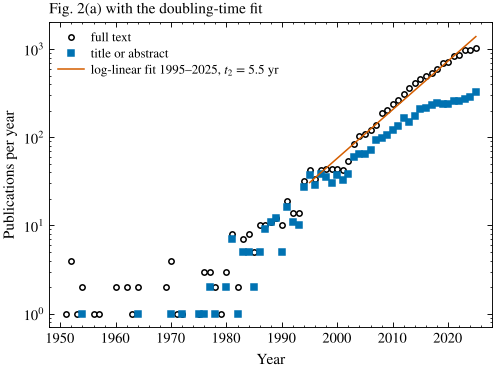

Fig. 2(a): 65 + 54 points identical to fig02_usage.csv


In [6]:
yr = years.loc[1950:2025]
fig, ax = plt.subplots(figsize=(5.2, 3.6))
ft_pts = yr.full_text[yr.full_text > 0]; ta_pts = yr.title_or_abstract[yr.title_or_abstract > 0]
ax.semilogy(ft_pts.index, ft_pts.values, "o", ms=3.5, mfc="white", mec=C["black"], label="full text")
ax.semilogy(ta_pts.index, ta_pts.values, "s", ms=3.5, color=C["blue"], label="title or abstract")
fit = yr.full_text.loc[1995:2025]
coef = np.polyfit(fit.index, np.log(fit.values), 1)
ax.semilogy(fit.index, np.exp(np.polyval(coef, fit.index)), "-", color=C["red"], lw=1,
            label=f"log-linear fit 1995–2025, $t_2$ = {np.log(2)/coef[0]:.1f} yr")
ax.set(xlim=(1948, 2028), ylim=(0.7, 2000), xlabel="Year", ylabel="Publications per year")
ax.legend(loc="upper left", fontsize=8.5); ax.set_title("Fig. 2(a) with the doubling-time fit", loc="left", fontsize=10)
plt.show()

ref2 = pd.read_csv(FIGDATA / "fig02_usage.csv", comment="#")
for lab, pts in [("full text", ft_pts), ("title or abstract", ta_pts)]:
    r = ref2[(ref2.panel == "(a)") & (ref2.series == lab)].sort_values("index")
    assert np.array_equal(r.x.values, pts.index.values) and np.array_equal(r.y.values, pts.values)
print(f"Fig. 2(a): {len(ft_pts)} + {len(ta_pts)} points identical to fig02_usage.csv")

## 2. Which communities use the model (Fig. 2b)

OpenAlex assigns each work a primary topic. `scripts/fig02_usage.py` groups the topics into nine application areas; we copy that mapping and recount.

In [7]:
topics = pd.DataFrame(B["top_topics_title_abstract"], columns=["topic", "works"])
GROUPS = {   # mapping used in scripts/fig02_usage.py
    "Fluid mechanics and computation": ["Rheology and Fluid Dynamics Studies", "Fluid Dynamics and Mixing",
        "Fluid Dynamics Simulations and Interactions", "Fluid Dynamics and Heat Transfer", "Heat Transfer and Optimization",
        "Hydraulic flow and structures"],
    "Drilling, oil and gas": ["Drilling and Well Engineering", "Petroleum Processing and Analysis",
        "Enhanced Oil Recovery Techniques", "Hydraulic Fracturing and Reservoir Analysis"],
    "Foods and biopolymers": ["Polysaccharides Composition and Applications", "Food composition and properties",
        "Proteins in Food Systems"],
    "Construction materials, grouts": ["Concrete and Cement Materials Research",
        "Innovations in Concrete and Construction Materials", "Grouting, Rheology, and Soil Mechanics"],
    "Mudflows, tailings, slurries": ["Landslides and related hazards", "Tailings Management and Properties",
        "Coal Combustion and Slurry Processing"],
    "MR and ER fluids": ["Vibration Control and Rheological Fluids"],
    "Blood and biomedicine": ["Blood properties and coagulation"],
    "Lubricants and greases": ["Tribology and Lubrication Engineering", "Lubricants and Their Additives"],
    "3D printing": ["Additive Manufacturing and 3D Printing Technologies"],
}
topic_to_group = {t: g for g, ts in GROUPS.items() for t in ts}
topics["group"] = topics.topic.map(topic_to_group)
by_group = topics.dropna(subset=["group"]).groupby("group").works.sum().sort_values()
print(f"{len(topics)} topics listed; the nine groups contain {by_group.sum()} of {B['title_abstract_total']} works "
      f"(article: 3 726 of 4 883)")
assert by_group.sum() == 3726

r = ref2[ref2.panel == "(b)"]
assert dict(zip(r.category, r.x_end.astype(int))) == by_group.to_dict()
print("Fig. 2(b): group totals identical to fig02_usage.csv")
by_group.to_frame("works with HB in title or abstract")

25 topics listed; the nine groups contain 3726 of 4883 works (article: 3 726 of 4 883)
Fig. 2(b): group totals identical to fig02_usage.csv


,works with HB in title or abstract
group,
3D printing,38
Lubricants and greases,84
Blood and biomedicine,167
MR and ER fluids,216
"Mudflows, tailings, slurries",224
"Construction materials, grouts",246
Foods and biopolymers,412
"Drilling, oil and gas",645
Fluid mechanics and computation,1694


## 3. HB compared with the Bingham and Casson models (Fig. 2c)

The Bingham model is named in about as many titles and abstracts as HB, and the Casson model in fewer. The review's point is not the number of users but their variety. We rebuild the field composition from the counts by OpenAlex research field, grouping the fields into six classes as in the script.

In [8]:
mc = B["model_comparison"]["models"]
long = pd.concat([pd.DataFrame(m["by_field"], columns=["field", "works"]).assign(model=k) for k, m in mc.items()])
CLASSES = {"Engineering": ["Engineering"], "Chemical engineering": ["Chemical Engineering"],
           "Agricultural and biological sciences": ["Agricultural and Biological Sciences"],
           "Medicine and health": ["Medicine", "Nursing", "Health Professions", "Pharmacology, Toxicology and Pharmaceutics",
                                   "Dentistry", "Neuroscience", "Immunology and Microbiology"],
           "Environmental and Earth sciences": ["Environmental Science", "Earth and Planetary Sciences"]}
field_to_class = {f: c for c, fs in CLASSES.items() for f in fs}
long["class"] = long.field.map(field_to_class).fillna("Other fields")
share = long.pivot_table(index="model", columns="class", values="works", aggfunc="sum", fill_value=0)
share = share[list(CLASSES) + ["Other fields"]].loc[["HB", "Bingham", "Casson"]]
share_pct = 100 * share.div(share.sum(axis=1), axis=0)
share_pct.round(1)

class,Engineering,Chemical engineering,Agricultural and biological sciences,Medicine and health,Environmental and Earth sciences,Other fields
model,,,,,,
HB,42.0,29.7,9.4,7.0,4.8,7.1
Bingham,61.8,23.3,1.3,1.6,5.3,6.8
Casson,77.2,7.0,2.7,6.8,0.2,6.1


In [9]:
summary = pd.DataFrame({
    "works (title/abstract)": {k: m["works"] for k, m in mc.items()},
    "share outside engineering (%)": 100 - share_pct[["Engineering", "Chemical engineering"]].sum(axis=1),
    "research fields": {k: m["fields"] for k, m in mc.items()},
    "subfields": {k: m["subfields"] for k, m in mc.items()},
    "agricultural & biological sciences works": share["Agricultural and biological sciences"],
}).loc[["HB", "Bingham", "Casson"]]
for k in summary.index:   # consistent with the stored percentages and the article (28, 15, 16 %)
    assert abs(summary.loc[k, "share outside engineering (%)"] - mc[k]["share_outside_engineering_pct"]) < 0.05
summary.round(1)

,works (title/abstract),share outside engineering (%),research fields,subfields,agricultural & biological sciences works
HB,4883,28.2,22,84,458
Bingham,5179,14.9,18,75,65
Casson,3732,15.8,19,54,101


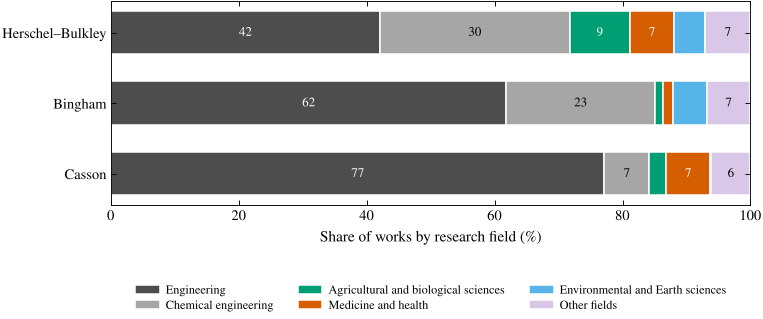

Fig. 2(c): all 18 bar widths agree with fig02_usage.csv (largest difference 5.6e-09 percentage points)


In [10]:
fig, ax = plt.subplots(figsize=(7.5, 2.4))
cols6 = ["#4d4d4d", "#a6a6a6", C["green"], C["red"], C["cyan"], "#d9c7e8"]
labels = {"HB": "Herschel–Bulkley", "Bingham": "Bingham", "Casson": "Casson"}
for yi, model in enumerate(share_pct.index):
    left = 0.0
    for cls, col in zip(share_pct.columns, cols6):
        wdt = share_pct.loc[model, cls]
        ax.barh(yi, wdt, left=left, color=col, edgecolor="white", height=0.62, label=cls if yi == 0 else None)
        if wdt >= 6:
            ax.text(left + wdt / 2, yi, f"{wdt:.0f}", ha="center", va="center", fontsize=8.5,
                    color="white" if col in ("#4d4d4d", C["red"], C["green"]) else "black")
        left += wdt
ax.set_yticks(range(3)); ax.set_yticklabels([labels[m] for m in share_pct.index]); ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel="Share of works by research field (%)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=3, fontsize=8); ax.minorticks_off()
plt.show()

r = ref2[ref2.panel == "(c)"].copy()
r["model"] = r.series.str.split(":").str[0]; r["cls"] = r.series.str.extract(r": (.*) \(% of works\)")[0]
inv = {v: k for k, v in labels.items()}
worst = max(abs((row.x_end - row.x) - share_pct.loc[inv[row.model], row.cls]) for row in r.itertuples())
assert worst < 1e-6
print(f"Fig. 2(c): all 18 bar widths agree with fig02_usage.csv (largest difference {worst:.1e} percentage points)")

About 28% of the HB works are classified outside engineering and chemical engineering, against 15% for Bingham and 16% for Casson; HB spans 22 of the 26 OpenAlex research fields and 84 subfields, and has 458 works in the agricultural and biological sciences (which include food science) against 65 and 101. The counts carry the caveats above, but they point in one direction: of the three yield-stress models, HB has traveled furthest beyond engineering.

## 4. The parameter atlas (Fig. 3)

`hb_parameter_atlas.csv` collects HB yield stresses and flow indices reported, in studies cited in the review, for 26 materials. Every row names its source and the table, section or data file the values come from. The values are **as reported, not refitted**, so they inherit each study's protocol, geometry and rate window.

In [11]:
atlas = pd.read_csv(DATA / "hb_parameter_atlas.csv")
print(atlas.shape[0], "rows;", atlas["class"].nunique(), "classes")
atlas[["material", "class", "sigma_y_Pa", "sigma_y_max_Pa", "n", "K_Pa_s_n", "source_key"]]

26 rows; 6 classes


,material,class,sigma_y_Pa,sigma_y_max_Pa,n,K_Pa_s_n,source_key
0,Rubber in benzene 0.69 wt%,1926 rubber solutions,0.0000,NaN,0.8100,NaN,HerschelBulkley1926
1,Rubber in benzene 1.0 wt%,1926 rubber solutions,0.0000,NaN,0.7400,NaN,HerschelBulkley1926
2,Rubber in benzene 1.2 wt%,1926 rubber solutions,0.0000,NaN,0.6800,NaN,HerschelBulkley1926
3,Used drilling fluid (fit 0-1000 1/s),Drilling and well fluids,0.2000,NaN,0.9806,0.0229,SaasenYtrehus2020
4,Used drilling fluid (fit 0-300 1/s),Drilling and well fluids,0.2000,NaN,0.8269,0.0548,SaasenYtrehus2020
5,Water-based drilling fluid,Drilling and well fluids,4.2900,NaN,0.5200,0.7000,SkadsemSaasen2019
6,Water-based spacer,Drilling and well fluids,5.7900,NaN,0.5400,0.7800,SkadsemSaasen2019
7,Cement slurry,Drilling and well fluids,1.0000,NaN,0.6900,1.0800,SkadsemSaasen2019
8,Colloidal gas aphrons XG 1000 ppm,Foams and aphrons,0.3291,NaN,0.7100,0.1370,Zhumabek2025
9,Colloidal gas aphrons XG 2000 ppm,Foams and aphrons,0.6081,NaN,0.6000,0.6080,Zhumabek2025


In [12]:
# Summary by class. Rows with a sigma_y range (sigma_y_max_Pa) contribute both ends.
a = atlas.assign(sigma_y_hi=atlas.sigma_y_max_Pa.fillna(atlas.sigma_y_Pa))
by_class = a.groupby("class").agg(rows=("material", "size"),
                                  sigma_y_min=("sigma_y_Pa", "min"), sigma_y_max=("sigma_y_hi", "max"),
                                  n_min=("n", "min"), n_max=("n", "max"))
by_class.sort_values("n_max")

,rows,sigma_y_min,sigma_y_max,n_min,n_max
class,,,,,
Clay suspensions,1,309.0000,309.00,0.333,0.3330
Emulsions,5,11.6000,77.00,0.333,0.5500
Carbopol and polymer gels,5,1.1980,133.00,0.310,0.6389
Foams and aphrons,7,0.3291,30.30,0.240,0.7100
1926 rubber solutions,3,0.0000,0.00,0.680,0.8100
Drilling and well fluids,5,0.2000,5.79,0.520,0.9806


In [13]:
mod = a[a["class"] != "1926 rubber solutions"]                     # sigma_y = 0 by reanalysis (notebook 01)
sy_all = pd.concat([mod.sigma_y_Pa, mod.sigma_y_max_Pa.dropna()])
print(f"yield stresses: {sy_all.min()} to {sy_all.max()} Pa, i.e. {np.log10(sy_all.max()/sy_all.min()):.1f} decades")
others = mod[mod.source_key != "SaasenYtrehus2020"]
print(f"flow index, all except the drilling fluid of Saasen and Ytrehus: {others.n.min()} to {others.n.max()}")
soft = mod[mod["class"].isin(["Emulsions", "Carbopol and polymer gels"]) | mod.material.str.startswith("SLES")]
print(f"foams, emulsions, microgel and polymer gels: n = {soft.n.min()} to {soft.n.max():.2f} (article: about 0.3-0.65)")
cga = mod[mod.material.str.startswith("Colloidal gas aphrons")]
print("colloidal gas aphrons (increasing xanthan gum):", list(zip(cga.sigma_y_Pa.round(2), cga.n)))
win = mod[mod.source_key == "SaasenYtrehus2020"]
print(f"same drilling fluid, fit window 0-1000 vs 0-300 1/s: n = {win.n.iloc[0]} -> {win.n.iloc[1]} "
      f"(shift {win.n.iloc[0] - win.n.iloc[1]:.2f})")
assert sy_all.min() == 0.2 and sy_all.max() == 309 and others.n.min() == 0.24 and others.n.max() == 0.71

yield stresses: 0.2 to 309.0 Pa, i.e. 3.2 decades
flow index, all except the drilling fluid of Saasen and Ytrehus: 0.24 to 0.71
foams, emulsions, microgel and polymer gels: n = 0.31 to 0.64 (article: about 0.3-0.65)
colloidal gas aphrons (increasing xanthan gum): [(0.33, 0.71), (0.61, 0.6), (0.87, 0.35), (1.84, 0.28), (2.66, 0.24), (4.92, 0.26)]
same drilling fluid, fit window 0-1000 vs 0-300 1/s: n = 0.9806 -> 0.8269 (shift 0.15)


These are the numbers quoted in Sec. III B: yield stresses from 0.2 Pa (a used drilling fluid) to 309 Pa (a kaolin suspension); apart from that drilling fluid, flow indices between 0.24 and 0.71; foams, emulsions and microgel and polymer gels between about 0.3 and 0.65; colloidal gas aphrons (Zhumabek et al. 2025) moving from $n = 0.71$ toward 0.25 as their yield stress grows. The window shift of 0.15 in $n$ for *one* fluid is comparable to the differences between material classes, a warning that anticipates Sec. VI D.

Now Fig. 3, redrawn from the atlas, and the check that the figure data contain the atlas rows, plus one row for the fresh-concrete exponent range drawn in the right-hand strip of Fig. 3.

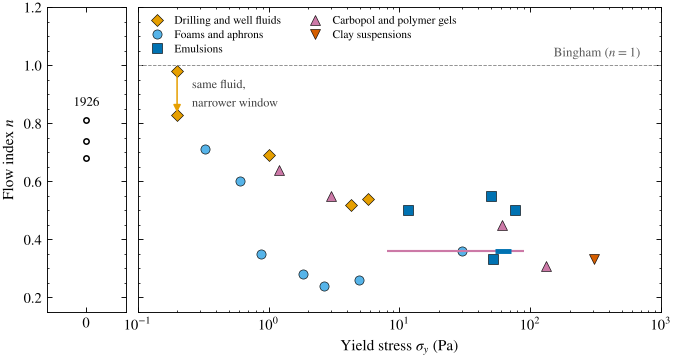

(fresh concrete, n = 1.10-1.88 (de Larrard et al. 1998), with yield stresses not compiled, is drawn as a
 separate strip in Fig. 3 and omitted from this redraw)
Fig. 3: fig03_parameter_atlas.csv contains the 26 atlas rows plus 'Fresh concrete (range of reported exponents)' (n = 1.10-1.88, deLarrard1998)


In [14]:
STYLE = {"Drilling and well fluids": (C["orange"], "D"), "Foams and aphrons": (C["cyan"], "o"),
         "Emulsions": (C["blue"], "s"), "Carbopol and polymer gels": (C["purple"], "^"), "Clay suspensions": (C["red"], "v")}
fig, (ax0, ax) = plt.subplots(1, 2, figsize=(7.2, 3.6), sharey=True, gridspec_kw={"width_ratios": [0.15, 1], "wspace": 0.04})
for cls, (col, mk) in STYLE.items():
    rows = atlas[atlas["class"] == cls]
    pts = rows[rows.sigma_y_max_Pa.isna()]; rng_rows = rows[rows.sigma_y_max_Pa.notna()]
    ax.plot(pts.sigma_y_Pa, pts.n, mk, ls="none", color=col, mec="k", mew=0.4, ms=6, label=cls)
    for rr in rng_rows.itertuples():                      # a range of sigma_y fitted with a common n
        ax.plot([rr.sigma_y_Pa, rr.sigma_y_max_Pa], [rr.n, rr.n], color=col, solid_capstyle="butt",
                lw=3.2 if cls == "Emulsions" else 1.4, zorder=4 if cls == "Emulsions" else 3)
ax.axhline(1.0, color="0.55", lw=0.6, ls="--"); ax.text(700, 1.03, "Bingham ($n=1$)", ha="right", fontsize=8.5, color="0.35")
ax.annotate("", xy=(0.2, win.n.iloc[1]), xytext=(0.2, win.n.iloc[0]), arrowprops=dict(arrowstyle="-|>", color=C["orange"]))
ax.text(0.26, 0.90, "same fluid,\nnarrower window", fontsize=8, color="0.25", va="center")
ax.set(xscale="log", xlim=(0.1, 1000), ylim=(0.15, 1.2), xlabel=r"Yield stress $\sigma_y$ (Pa)")
ax.legend(loc="upper left", fontsize=7.5, ncol=2)
rub = atlas[atlas["class"] == "1926 rubber solutions"]
ax0.plot(np.zeros(len(rub)), rub.n, "o", mfc="white", mec="k"); ax0.set_xlim(-1, 1); ax0.set_xticks([0])
ax0.set_ylabel("Flow index $n$"); ax0.text(0, 0.86, "1926", ha="center", fontsize=8.5)
plt.show()
print("(fresh concrete, n = 1.10-1.88 (de Larrard et al. 1998), with yield stresses not compiled, is drawn as a\n"
      " separate strip in Fig. 3 and omitted from this redraw)")

ref3 = pd.read_csv(FIGDATA / "fig03_parameter_atlas.csv", comment="#")
in_atlas = ref3.material.isin(atlas.material)
# the n column also holds the concrete range "1.10-1.88" as text, so convert the atlas rows to numbers first
pd.testing.assert_frame_equal(ref3[in_atlas].reset_index(drop=True).astype({"n": float}),
                              atlas.reset_index(drop=True), check_dtype=False)
concrete = ref3[~in_atlas]
assert len(concrete) == 1 and concrete.n.iloc[0] == "1.10-1.88"
print(f"Fig. 3: fig03_parameter_atlas.csv contains the {in_atlas.sum()} atlas rows plus "
      f"'{concrete.material.iloc[0]}' (n = {concrete.n.iloc[0]}, {concrete.source_key.iloc[0]})")

### Why a shared $n$ does not imply a shared mechanism

Several very different materials in the atlas report $n\approx0.5$. Table I of the review lists their microstructures, and Table VI the theories that predict exponents near one half:

In [15]:
MICRO = {   # microstructure, from Table I of the review
    "Emulsions": "jammed deformable droplets",
    "Carbopol and polymer gels": "jammed swollen polymer particles (microgels)",
    "Drilling and well fluids": "clay, polymer and emulsion blends",
    "Foams and aphrons": "jammed bubbles",
    "Clay suspensions": "attractive particle network",
}
near_half = atlas[(atlas.n - 0.5).abs() <= 0.05 + 1e-9].assign(microstructure=lambda d: d["class"].map(MICRO))
near_half[["material", "class", "microstructure", "sigma_y_Pa", "n", "source_key"]]

,material,class,microstructure,sigma_y_Pa,n,source_key
5,Water-based drilling fluid,Drilling and well fluids,"clay, polymer and emulsion blends",4.29,0.52,SkadsemSaasen2019
6,Water-based spacer,Drilling and well fluids,"clay, polymer and emulsion blends",5.79,0.54,SkadsemSaasen2019
15,Concentrated emulsion (wide-gap MRI),Emulsions,jammed deformable droplets,77.00,0.50,Ovarlez2008PRE
16,Concentrated emulsion (phi 0.75),Emulsions,jammed deformable droplets,11.60,0.50,Goyon2008
17,Clay-free emulsion,Emulsions,jammed deformable droplets,50.50,0.55,Fall2010
20,Carbopol hair gel,Carbopol and polymer gels,jammed swollen polymer particles (microgels),61.00,0.45,Coussot2009JNNFM
21,Carbopol (pillar array),Carbopol and polymer gels,jammed swollen polymer particles (microgels),3.00,0.55,Waisbord2019


Droplets pressed against each other, swollen microgel particles and a clay–polymer drilling fluid (Skadsem and Saasen 2019) share $n\approx0.5$ but little else. Table VI of the review shows why the coincidence is not evidence of a common cause: mean-field mechanical noise (Hébraud and Lequeux 1998), kinetic elastoplastic fluidity (Bocquet et al. 2009) and soft-particle elastohydrodynamics (Seth et al. 2011) all predict $n = 1/2$ by different routes; elastoplastic avalanches predict $n\approx0.6$ in three dimensions (Lin and Wyart 2018); and for attractive gels the exponent is an effective, state-dependent number. Distinguishing mechanisms needs a second controlled variable, such as the solvent viscosity, the particle modulus or the distance from jamming, not a better fit at fixed state.

Two analysis effects make fitted exponents window-dependent even when the microscopic law is known (Sec. V C). The first is a crossover between contributions. If a plastic power law is supplemented by a solvent term,

$$\sigma = \sigma_y + A(\dot\gamma/\dot\gamma_*)^{n_0} + \eta_s\dot\gamma,\qquad n_{\rm eff} = \frac{n_0A(\dot\gamma/\dot\gamma_*)^{n_0} + \eta_s\dot\gamma}{A(\dot\gamma/\dot\gamma_*)^{n_0} + \eta_s\dot\gamma}, \tag{13–14}$$

the local slope of the excess stress rises from $n_0$ toward one as the solvent term grows, and a three-parameter HB fit across the crossover has no reason to return $n_0$. The cell below makes this concrete with illustrative numbers (our own example): one material with $n_0 = 0.5$, fitted in two rate windows.

In [16]:
from scipy.optimize import curve_fit
sy0, A0, n0, gstar, eta_s = 10.0, 5.0, 0.5, 1.0, 0.05           # Pa, Pa, -, 1/s, Pa s  (illustrative)
true_curve = lambda g: sy0 + A0 * (g / gstar)**n0 + eta_s * g
n_eff = lambda g: (n0 * A0 * (g / gstar)**n0 + eta_s * g) / (A0 * (g / gstar)**n0 + eta_s * g)
for lo, hi in [(1e-2, 1e1), (1e1, 1e4)]:
    g = np.logspace(np.log10(lo), np.log10(hi), 30)
    p, _ = curve_fit(lambda x, s, k, m: np.log(s + k * x**m), g, np.log(true_curve(g)), p0=[5, 5, 0.6],
                     bounds=([0, 1e-6, 0.05], [100, 1e3, 2]))
    print(f"window {lo:g}-{hi:g} 1/s: n_eff from {n_eff(lo):.2f} to {n_eff(hi):.2f}; "
          f"HB fit gives sigma_y = {p[0]:.1f} Pa, n = {p[2]:.2f}  (microscopic n0 = {n0})")

window 0.01-10 1/s: n_eff from 0.50 to 0.52; HB fit gives sigma_y = 10.0 Pa, n = 0.51  (microscopic n0 = 0.5)
window 10-10000 1/s: n_eff from 0.52 to 0.75; HB fit gives sigma_y = 17.2 Pa, n = 0.65  (microscopic n0 = 0.5)


The same material gives $n\approx0.5$ in one window and a much larger index in the other. Caggioni et al. (2020) demonstrated this experimentally by changing the viscosity of the continuous phase of concentrated emulsions.

**A note on comparing $K$.** The consistency has units Pa s$^n$ that change with $n$, so its values cannot be compared across materials with different $n$. The reparameterizations of Sec. IV C help: the rate $\dot\gamma_y = (\sigma_y/K)^{1/n}$ at which the flow stress is twice the yield stress (Nelson and Ewoldt 2017), or the excess stress $A = K\dot\gamma_*^{\,n}$ at a reference rate. We compute both for the atlas rows that report $K$ (with $\dot\gamma_* = 100$ s$^{-1}$, our choice).

In [17]:
withK = atlas.dropna(subset=["K_Pa_s_n"]).query("sigma_y_Pa > 0").copy()
withK["gdot_y (1/s)"] = (withK.sigma_y_Pa / withK.K_Pa_s_n)**(1 / withK.n)
withK["A at 100 1/s (Pa)"] = withK.K_Pa_s_n * 100.0**withK.n
withK.sort_values("gdot_y (1/s)")[["material", "sigma_y_Pa", "K_Pa_s_n", "n", "gdot_y (1/s)", "A at 100 1/s (Pa)"]].round(3)

,material,sigma_y_Pa,K_Pa_s_n,n,gdot_y (1/s),A at 100 1/s (Pa)
12,Colloidal gas aphrons XG 8000 ppm,2.665,5.150,0.240,0.064,15.553
10,Colloidal gas aphrons XG 4000 ppm,0.873,1.664,0.350,0.158,8.340
11,Colloidal gas aphrons XG 6000 ppm,1.841,3.020,0.280,0.171,10.965
13,Colloidal gas aphrons XG 10000 ppm,4.925,5.620,0.260,0.602,18.610
7,Cement slurry,1.000,1.080,0.690,0.894,25.907
9,Colloidal gas aphrons XG 2000 ppm,0.608,0.608,0.600,1.000,9.636
16,Concentrated emulsion (phi 0.75),11.600,11.200,0.500,1.073,112.000
8,Colloidal gas aphrons XG 1000 ppm,0.329,0.137,0.710,3.436,3.603
4,Used drilling fluid (fit 0-300 1/s),0.200,0.055,0.827,4.786,2.469
21,Carbopol (pillar array),3.000,1.200,0.550,5.291,15.107


## 5. Which kinds of test does the model pass? (Table XII and Fig. 13)

Section IX of the review collects experiments in which parameters measured in a rheometer were used to predict a *different* flow. Fig. 13 encodes, for each study, what changes between calibration and test (five columns) and the main finding, in three categories: predicted with the shear parameters; predicted after an extension, a fitted coefficient or a parameter change; or physics not captured by the baseline model. The figure data are a table, which we load and pivot.

In [18]:
tm = pd.read_csv(FIGDATA / "fig13_transfer_matrix.csv", comment="#")
COLS = ["Local flow curve", "Flow type", "Geometry, scale", "Walls, gap", "History, time"]
SHORT = {"predicted with shear parameters": "predicted", "predicted after extension or refit": "extended",
         "not captured by the baseline model": "not captured"}
tm["outcome"] = tm.finding.map(SHORT)
print(f"{len(tm)} (study, column) entries for {tm.study.nunique()} rows of Fig. 13")
matrix = (tm.pivot_table(index=["group", "study"], columns="what changes", values="outcome", aggfunc="first")
            .reindex(columns=COLS).fillna(""))
matrix = matrix.loc[tm.drop_duplicates("study").set_index(["group", "study"]).index]   # keep the figure order
print("P = predicted with shear parameters, E = predicted after extension or refit, N = not captured")
matrix.replace({"predicted": "P", "extended": "E", "not captured": "N"})

27 (study, column) entries for 22 rows of Fig. 13
P = predicted with shear parameters, E = predicted after extension or refit, N = not captured


what changes                                           Local flow curve  \
group study                                                               
A     Emulsions, wide-gap MRI (Ovarlez 2008)                          P   
      Carbopol gel, MRI and cone–plate (Coussot 2009)                 P   
      Foam, local MRI (Ovarlez, Krishan 2010)                         P   
B     Emulsion in microchannels (Goyon 2008)                              
      Adhesive emulsion, smooth narrow gap (Bécu 2006)                    
C     Clay-loaded emulsion (Fall 2010)                                    
      Bentonite, rest-time series (Møller 2006)                           
D     Rotation plus squeeze (Ovarlez, Barral 2010)                        
      Normal stresses (de Cagny 2019)                                     
      Capillary thinning, onset (Martinie 2013)                           
      Slipping plates (Zhang 2018)                                        
      Gravity filaments, onset (Geffrault 2021)                           
      Gravity filaments, flow curve (Geffrault 2021)                      
      Cross-slot, EVP model (Varchanis 2020)                              
E     Sphere drag and arrest (Tabuteau 2007)                              
      Flow field around sphere (Putz 2008)                                
F     Pipe rheometer (Magnon 2021)                                        
      Free-surface channel, kaolin (Chambon 2014)                         
      Free-surface channel, Carbopol (Chambon 2014)                       
G     Bead packings, pressure drop (Chevalier 2013)                       
      Bead packing, NMR field (Chevalier 2014)                            
      Pillar array (Waisbord 2019)                                        

what changes                                           Flow type  \
group study                                                        
A     Emulsions, wide-gap MRI (Ovarlez 2008)                       
      Carbopol gel, MRI and cone–plate (Coussot 2009)              
      Foam, local MRI (Ovarlez, Krishan 2010)                      
B     Emulsion in microchannels (Goyon 2008)                       
      Adhesive emulsion, smooth narrow gap (Bécu 2006)             
C     Clay-loaded emulsion (Fall 2010)                             
      Bentonite, rest-time series (Møller 2006)                    
D     Rotation plus squeeze (Ovarlez, Barral 2010)             P   
      Normal stresses (de Cagny 2019)                          N   
      Capillary thinning, onset (Martinie 2013)                P   
      Slipping plates (Zhang 2018)                             N   
      Gravity filaments, onset (Geffrault 2021)                P   
      Gravity filaments, flow curve (Geffrault 2021)           E   
      Cross-slot, EVP model (Varchanis 2020)                   E   
E     Sphere drag and arrest (Tabuteau 2007)                       
      Flow field around sphere (Putz 2008)                         
F     Pipe rheometer (Magnon 2021)                                 
      Free-surface channel, kaolin (Chambon 2014)                  
      Free-surface channel, Carbopol (Chambon 2014)                
G     Bead packings, pressure drop (Chevalier 2013)                
      Bead packing, NMR field (Chevalier 2014)                     
      Pillar array (Waisbord 2019)                                 

what changes                                           Geometry, scale  \
group study                                                              
A     Emulsions, wide-gap MRI (Ovarlez 2008)                             
      Carbopol gel, MRI and cone–plate (Coussot 2009)                    
      Foam, local MRI (Ovarlez, Krishan 2010)                            
B     Emulsion in microchannels (Goyon 2008)                             
      Adhesive emulsion, smooth narrow gap (Bécu 2006)                   
C     Clay-loaded emulsion (Fall 2010)          

**Consistency with Table XII.** Table XII states the main finding of each study in words. We transcribe those verdicts and check that each row of Fig. 13 carries the matching symbol. (Geffrault et al. 2021 is "mixed" in Table XII and occupies two rows of Fig. 13: onset predicted, flow curve refitted.)

In [19]:
TABLE_XII = {   # main finding of each study, transcribed from Table XII of the review
    "Emulsions, wide-gap MRI (Ovarlez 2008)": "predicted",
    "Carbopol gel, MRI and cone–plate (Coussot 2009)": "predicted",
    "Foam, local MRI (Ovarlez, Krishan 2010)": "predicted",
    "Emulsion in microchannels (Goyon 2008)": "extended",
    "Adhesive emulsion, smooth narrow gap (Bécu 2006)": "not captured",
    "Clay-loaded emulsion (Fall 2010)": "not captured",
    "Bentonite, rest-time series (Møller 2006)": "not captured",
    "Rotation plus squeeze (Ovarlez, Barral 2010)": "predicted",
    "Normal stresses (de Cagny 2019)": "not captured",
    "Capillary thinning, onset (Martinie 2013)": "predicted",
    "Slipping plates (Zhang 2018)": "not captured",
    "Gravity filaments, onset (Geffrault 2021)": "predicted",       # Table XII: "Mixed: onset predicted"
    "Gravity filaments, flow curve (Geffrault 2021)": "extended",  # Table XII: "n refitted"
    "Cross-slot, EVP model (Varchanis 2020)": "extended",
    "Sphere drag and arrest (Tabuteau 2007)": "predicted",
    "Flow field around sphere (Putz 2008)": "not captured",
    "Pipe rheometer (Magnon 2021)": "extended",
    "Free-surface channel, kaolin (Chambon 2014)": "predicted",
    "Free-surface channel, Carbopol (Chambon 2014)": "extended",
    "Bead packings, pressure drop (Chevalier 2013)": "extended",
    "Bead packing, NMR field (Chevalier 2014)": "not captured",
    "Pillar array (Waisbord 2019)": "extended",
}
per_study = tm.groupby("study").outcome.agg(lambda s: set(s))
assert set(per_study.index) == set(TABLE_XII)
for study, outcomes in per_study.items():
    assert outcomes == {TABLE_XII[study]}, study
print(f"all {len(TABLE_XII)} rows of Fig. 13 match the verdicts of Table XII")

all 22 rows of Fig. 13 match the verdicts of Table XII


In [20]:
# Tabulations: per study row, per kind of change, per group
study_outcome = pd.Series(TABLE_XII).reindex(matrix.index.get_level_values("study"))
print("rows of Fig. 13 by outcome:\n", study_outcome.value_counts().to_string(), "\n")
by_column = pd.crosstab(tm["what changes"], tm.outcome).reindex(COLS)[["predicted", "extended", "not captured"]]
by_column["total"] = by_column.sum(axis=1)
by_column

rows of Fig. 13 by outcome:
 predicted       8
extended        7
not captured    7 



outcome,predicted,extended,not captured,total
what changes,,,,
Local flow curve,3,0,0,3
Flow type,3,2,2,7
"Geometry, scale",2,4,2,8
"Walls, gap",0,3,1,4
"History, time",1,1,3,5


In [21]:
GROUP_NAMES = {"A": "local rheology in wide gaps", "B": "confinement and walls", "C": "thixotropy", "D": "flow type",
               "E": "obstacles", "F": "conduits and free-surface channels", "G": "porous media"}
rows_df = matrix.reset_index()[["group", "study"]].assign(outcome=lambda d: d.study.map(TABLE_XII))
by_group = pd.crosstab(rows_df.group, rows_df.outcome)[["predicted", "extended", "not captured"]]
SECTION = {"A": "IX A", "B": "IX B", "C": "IX B", "D": "IX C", "E": "IX D", "F": "IX E", "G": "IX G"}  # Fig. 13 caption
by_group.index = [f"{g}: {GROUP_NAMES[g]} (Sec. {SECTION[g]})" for g in by_group.index]
by_group

outcome,predicted,extended,not captured
A: local rheology in wide gaps (Sec. IX A),3,0,0
B: confinement and walls (Sec. IX B),0,1,1
C: thixotropy (Sec. IX B),0,0,2
D: flow type (Sec. IX C),3,2,2
E: obstacles (Sec. IX D),1,0,1
F: conduits and free-surface channels (Sec. IX E),1,2,0
G: porous media (Sec. IX G),0,2,1


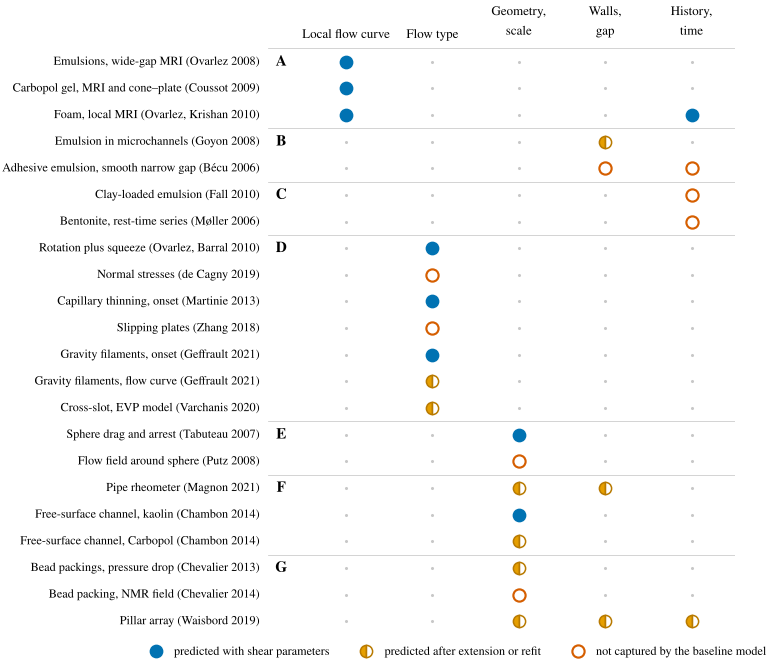

In [22]:
SYM = {"predicted": dict(marker="o", mfc=C["blue"], mec=C["blue"]),
       "extended": dict(marker="o", mfc=C["orange"], mec="#B87A00", fillstyle="left", markerfacecoloralt="white"),
       "not captured": dict(marker="o", mfc="white", mec=C["red"], mew=1.4)}
fig, ax = plt.subplots(figsize=(8.0, 6.4))
studies = list(matrix.index.get_level_values("study")); groups = list(matrix.index.get_level_values("group"))
N = len(studies)
for i, (g, s) in enumerate(zip(groups, studies)):
    y = N - 1 - i
    if i == 0 or groups[i - 1] != g:
        ax.axhline(y + 0.5, color=C["lightgrey"], lw=0.5); ax.text(-0.75, y, g, ha="center", va="center", fontweight="bold")
    for j, col in enumerate(COLS):
        out = matrix.loc[(g, s), col]
        ax.plot(j, y, ls="none", ms=8, **SYM[out]) if out else ax.plot(j, y, ".", color=C["lightgrey"], ms=2)
    ax.text(-1.0, y, s, ha="right", va="center", fontsize=8)
ax.set_xticks(range(5)); ax.set_xticklabels([c.replace(", ", ",\n") for c in COLS], fontsize=8.5); ax.xaxis.tick_top()
ax.set(xlim=(-0.9, 4.5), ylim=(-0.6, N - 0.4)); ax.set_yticks([]); ax.tick_params(length=0); ax.minorticks_off()
for sp in ax.spines.values(): sp.set_visible(False)
from matplotlib.lines import Line2D
ax.legend([Line2D([], [], ls="none", ms=8, **SYM[k]) for k in SYM],
          ["predicted with shear parameters", "predicted after extension or refit", "not captured by the baseline model"],
          loc="upper center", bbox_to_anchor=(0.4, 0.0), ncol=3, fontsize=8)
fig.subplots_adjust(left=0.45, right=0.98, top=0.9, bottom=0.06); plt.show()

**Group letters and review sections.** The group letters of Table XII and Fig. 13 are not the letters of the Sec. IX subsections. As the Fig. 13 caption states, group A is discussed in Sec. IX A, groups B and C in Sec. IX B, D in IX C, E in IX D, F in IX E and G in IX G (Sec. IX F, on spreading and imbibition, has no group because its forward models are not HB). The last column of the table above gives this mapping.

**Reading the tabulation.** The pattern summarized in Sec. IX H emerges directly from the counts:

- The **local flow curve** column (group A) is all "predicted": a careful measurement in a wide, rough gap gives the local law for simple yield-stress fluids.
- Changes of **flow type** split three ways: yielding under superposed shear, and the onset of yield in gravity-driven filaments and, for 11 of 17 materials, in capillary thinning, are predicted; the extensional flow curve and planar extension need refitting or an elastic modulus; normal stresses and elongation between slipping plates lie outside the baseline.
- Changes of **geometry and scale** succeed when the observable is governed by global force balance and viscous dissipation (sphere drag and arrest, uniform free-surface flow of kaolin); flow-field shapes (fore–aft asymmetry around a sphere, pore-scale velocity fields) are not captured.
- Every entry in **history, time** that is not a simple foam is "extended" or "not captured": thixotropy below a critical shear rate is the clearest frontier.

Because only one or two studies address each situation, the review reads these patterns as working guides rather than general laws. The same material can land in different columns: Carbopol predicts sphere drag but needs a 10–20% parameter increase in free-surface flow, gives low pipe intercepts on glass and jams in fine pores. Labeling material classes "HB" or "non-HB" is therefore less useful than asking what changes between calibration and use (the coordinates of Table XI).

## Try it yourself

**Exercise 1 — citations of the 1926 paper.** Estimate a doubling time for the yearly citations of the 1926 paper from 2012 to 2025 and compare it with the full-text doubling time over the same years. Do citations understate use, as the review says?
*Hint:* `doubling_time(years.citations_1926_paper, 2012, 2025)`.

<details><summary>Solution</summary>

```python
print("citations of the 1926 paper:", doubling_time(years.citations_1926_paper, 2012, 2025))
print("full-text mentions:         ", doubling_time(years.full_text, 2012, 2025))
print("citations per full-text mention, 2012 and 2025:",
      years.citations_1926_paper[2012] / years.full_text[2012], years.citations_1926_paper[2025] / years.full_text[2025])
```
From 2012 to 2025 the yearly citations double about every 5.8 years and the full-text mentions about every 7.4 years, so citations have grown at least as fast as use. Their level is what understates use: in both 2012 and 2025 there were only about 0.11–0.12 citations of the 1926 paper per work that mentions the model (113 against 1034 in 2025). As the review notes, most users cite a review or a textbook (Bird, Dai and Yarusso 1983; Chhabra and Richardson 2008), or no source at all.
</details>

**Exercise 2 — the topics that did not make it into Fig. 2(b).** Which OpenAlex topics are *not* mapped to any of the nine groups, and how many works do they hold? Would adding the largest of them change the ranking of the groups?

<details><summary>Solution</summary>

```python
unmapped = topics[topics.group.isna()].sort_values("works", ascending=False)
print(unmapped.head(10)); print("total:", unmapped.works.sum())
print("works in the 25 listed topics:", topics.works.sum(), "of", B["title_abstract_total"])
```
Only one of the 25 topics stored in the file is unmapped: "Material Dynamics and Properties", with 38 works. Added to any group it would not change the order of the nine groups, because the smallest group (3D printing) already has 38 works and the next (lubricants and greases) 84. The 25 listed topics hold 3764 of the 4883 works; the remaining 1119 are spread over smaller topics not stored in the file, which is why the nine groups hold 3726 works.
</details>

**Exercise 3 — Carbopol across the tests.** Select the rows of Fig. 13 whose study involves Carbopol (Coussot 2009, Tabuteau 2007, Magnon 2021, Chambon 2014 Carbopol, Chevalier 2013, Waisbord 2019) and tabulate their outcomes by column. Compare with the emulsion studies. What changes between calibration and test seem to matter for each material?
*Hint:* build a list of the study labels and use `tm[tm.study.isin(carbopol)]` with `pd.crosstab`.

<details><summary>Solution</summary>

```python
carbopol = ["Carbopol gel, MRI and cone–plate (Coussot 2009)", "Sphere drag and arrest (Tabuteau 2007)",
            "Pipe rheometer (Magnon 2021)", "Free-surface channel, Carbopol (Chambon 2014)",
            "Bead packings, pressure drop (Chevalier 2013)", "Pillar array (Waisbord 2019)"]
emulsion = ["Emulsions, wide-gap MRI (Ovarlez 2008)", "Emulsion in microchannels (Goyon 2008)",
            "Adhesive emulsion, smooth narrow gap (Bécu 2006)", "Clay-loaded emulsion (Fall 2010)"]
for lab, studies_ in [("Carbopol", carbopol), ("emulsions", emulsion)]:
    sub = tm[tm.study.isin(studies_)]
    assert sub.study.nunique() == len(studies_)
    print(lab); print(pd.crosstab(sub["what changes"], sub.outcome), "\n")
```
For the six Carbopol rows (nine entries) the local flow curve and sphere drag are predicted (two entries); the other seven are "extended": four changes of geometry and scale (pipe, free-surface channel, bead packing, pillar array), two of walls and gap and one of history. No Carbopol entry is "not captured". For the four emulsion rows the local flow curve is predicted, confinement in microchannels needs a nonlocal extension, and an adhesive emulsion in a smooth narrow gap and a clay-loaded emulsion show history-dependent banding that the baseline does not contain (three "not captured" entries). For Carbopol the decisive changes are scale, walls and pores; for the emulsions they are attraction between droplets, which brings thixotropy, and confinement. The material class alone does not decide the outcome.
</details>

**Exercise 4 — reference rate and ranking.** Rank the atlas rows that report $K$ by $A = K\dot\gamma_*^{\,n}$ at $\dot\gamma_* = 1$, 100 and 1000 s$^{-1}$. Does the ranking change? What does that imply for statements such as "material X is more viscous than material Y"?

<details><summary>Solution</summary>

```python
ranks = {}
for gs in (1.0, 100.0, 1000.0):
    ranks[f"rank at {gs:g} 1/s"] = (withK.K_Pa_s_n * gs**withK.n).rank(ascending=False).astype(int)
rk = pd.DataFrame(ranks).assign(material=withK.material).sort_values("rank at 1 1/s")
print(rk.to_string())
a, b = rk["rank at 1 1/s"], rk["rank at 1000 1/s"]
print("Spearman correlation 1 vs 1000 1/s:", a.corr(b, method="spearman"))
print("pairs whose order reverses:", sum((a[i] - a[j]) * (b[i] - b[j]) < 0 for i in rk.index for j in rk.index if i < j))
```
The ranking changes: of the 171 pairs of the 19 materials that report $K$, 29 reverse their order between 1 and 1000 s$^{-1}$ (Spearman correlation 0.80). For example, the Pluronic gel is second at 1 s$^{-1}$ but fifth at 1000 s$^{-1}$, the aphron with 4000 ppm xanthan gum falls from tenth to seventeenth, and the cement slurry rises from twelfth to sixth. Materials with a small $n$ lose rank at high rates. "Material X is more viscous than material Y" therefore holds only at a stated rate; comparisons of $K$ across different $n$, or of $A$ without the reference rate, are not meaningful (Sec. IV C).
</details>

## Key points
- The bibliometric counts are indicative (automatic topic labels, incomplete early full-text coverage), but they show steady growth: full-text mentions doubled about every 5.5 years from 1995 to 2025, with 97% of them since 2000; recent growth is slower.
- HB is named in about as many titles and abstracts as Bingham, but 28% of HB works lie outside engineering and chemical engineering, against 15–16% for Bingham and Casson: its distinctive achievement is breadth.
- Reported yield stresses span more than three decades (0.2–309 Pa) and flow indices mostly 0.24–0.71; a change of fitting window can shift $n$ of one fluid as much as the differences between classes.
- A shared $n$ does not imply a shared mechanism: several theories predict $n = 1/2$, attractive gels have state-dependent exponents, and crossovers and windows alter fitted indices. Compare materials with consistent-unit parameters ($\dot\gamma_y$ or $A$ at a stated rate).
- Of the 22 rows of Fig. 13, 8 were predicted with the shear parameters, 7 needed an extension or refit and 7 revealed physics outside the baseline; successes share simple yield-stress materials, rough walls and observables governed by global force balance.

## References

The review and its repository:
- Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

- J. Priem, H. Piwowar and R. Orr (2022). OpenAlex: A fully-open index of scholarly works, authors, venues, institutions, and concepts. arXiv:2205.01833. https://doi.org/10.48550/arXiv.2205.01833
- OurResearch (2026). OpenAlex: An open index of scholarly works. https://openalex.org. Queried 25 October 2026.
- W. H. Herschel and R. Bulkley (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**, 291–300. https://doi.org/10.1007/bf01432034
- R. B. Bird, G. C. Dai and B. J. Yarusso (1983). The Rheology and Flow of Viscoplastic Materials. *Reviews in Chemical Engineering* **1**, 1–70. https://doi.org/10.1515/revce-1983-0102
- R. P. Chhabra and J. F. Richardson (2008). Non-Newtonian Flow and Applied Rheology: Engineering Applications. 2nd ed., Butterworth-Heinemann, Oxford.
- A. Saasen and J. D. Ytrehus (2020). Viscosity models for drilling fluids—Herschel–Bulkley parameters and their use. *Energies* **13**, 5271. https://doi.org/10.3390/en13205271
- H. J. Skadsem and A. Saasen (2019). Concentric cylinder viscometer flows of Herschel–Bulkley fluids. *Applied Rheology* **29**, 173–181. https://doi.org/10.1515/arh-2019-0015
- M. Zhumabek, A. Kachkinova, M. Cochennec, S. Colombano, Y. Amanbek, Y. Wang and S. Omirbekov (2025). Stability and rheological characterization of colloidal gas aphrons: Influence of xanthan gum and sodium dodecyl sulfate. *Discover Applied Sciences* **7**, 432. https://doi.org/10.1007/s42452-025-06884-8
- G. Ovarlez, K. Krishan and S. Cohen-Addad (2010). Investigation of shear banding in three-dimensional foams. *EPL* **91**, 68005. https://doi.org/10.1209/0295-5075/91/68005
- G. Ovarlez, S. Rodts, A. Ragouilliaux, P. Coussot, J. Goyon and A. Colin (2008). Wide-gap Couette flows of dense emulsions: Local concentration measurements, and comparison between macroscopic and local constitutive law measurements through magnetic resonance imaging. *Physical Review E* **78**, 036307. https://doi.org/10.1103/PhysRevE.78.036307
- J. Goyon, A. Colin, G. Ovarlez, A. Ajdari and L. Bocquet (2008). Spatial cooperativity in soft glassy flows. *Nature* **454**, 84–87. https://doi.org/10.1038/nature07026
- A. Fall, J. Paredes and D. Bonn (2010). Yielding and shear banding in soft glassy materials. *Physical Review Letters* **105**, 225502. https://doi.org/10.1103/PhysRevLett.105.225502
- A. Geffrault, H. Bessaies-Bey, N. Roussel and P. Coussot (2021). Extensional gravity-rheometry (EGR) for yield stress fluids. *Journal of Rheology* **65**, 887–901. https://doi.org/10.1122/8.0000241
- T. Chevalier, C. Chevalier, X. Clain, J. C. Dupla, J. Canou, S. Rodts and P. Coussot (2013). Darcy's law for yield stress fluid flowing through a porous medium. *Journal of Non-Newtonian Fluid Mechanics* **195**, 57–66. https://doi.org/10.1016/j.jnnfm.2012.12.005
- P. Coussot, L. Tocquer, C. Lanos and G. Ovarlez (2009). Macroscopic vs. local rheology of yield stress fluids. *Journal of Non-Newtonian Fluid Mechanics* **158**, 85–90. https://doi.org/10.1016/j.jnnfm.2008.08.003
- N. Waisbord, N. Stoop, D. M. Walkama, J. Dunkel and J. S. Guasto (2019). Anomalous percolation flow transition of yield stress fluids in porous media. *Physical Review Fluids* **4**, 063303. https://doi.org/10.1103/PhysRevFluids.4.063303
- E. Magnon and E. Cayeux (2021). Precise Method to Estimate the Herschel–Bulkley Parameters from Pipe Rheometer Measurements. *Fluids* **6**, 157. https://doi.org/10.3390/fluids6040157
- S. Varchanis, S. J. Haward, C. C. Hopkins, A. Syrakos, A. Q. Shen, Y. Dimakopoulos and J. Tsamopoulos (2020). Transition between solid and liquid state of yield-stress fluids under purely extensional deformations. *Proceedings of the National Academy of Sciences* **117**, 12611–12617. https://doi.org/10.1073/pnas.1922242117
- F. de Larrard, C. F. Ferraris and T. Sedran (1998). Fresh concrete: A Herschel–Bulkley material. *Materials and Structures* **31**, 494–498. https://doi.org/10.1007/BF02480474
- A. Z. Nelson and R. H. Ewoldt (2017). Design of yield-stress fluids: a rheology-to-structure inverse problem. *Soft Matter* **13**, 7578–7594. https://doi.org/10.1039/C7SM00758B
- P. Hébraud and F. Lequeux (1998). Mode-Coupling Theory for the Pasty Rheology of Soft Glassy Materials. *Physical Review Letters* **81**, 2934–2937. https://doi.org/10.1103/physrevlett.81.2934
- L. Bocquet, A. Colin and A. Ajdari (2009). Kinetic Theory of Plastic Flow in Soft Glassy Materials. *Physical Review Letters* **103**, 036001. https://doi.org/10.1103/physrevlett.103.036001
- J. R. Seth, L. Mohan, C. Locatelli-Champagne, M. Cloitre and R. T. Bonnecaze (2011). A micromechanical model to predict the flow of soft particle glasses. *Nature Materials* **10**, 838–843. https://doi.org/10.1038/nmat3119
- J. Lin and M. Wyart (2018). Microscopic processes controlling the Herschel–Bulkley exponent. *Physical Review E* **97**, 012603. https://doi.org/10.1103/physreve.97.012603
- M. Caggioni, V. Trappe and P. T. Spicer (2020). Variations of the Herschel–Bulkley exponent reflecting contributions of the viscous continuous phase to the shear rate-dependent stress of soft glassy materials. *Journal of Rheology* **64**, 413–422. https://doi.org/10.1122/1.5120633
- L. Bécu, S. Manneville and A. Colin (2006). Yielding and flow in adhesive and nonadhesive concentrated emulsions. *Physical Review Letters* **96**, 138302. https://doi.org/10.1103/PhysRevLett.96.138302
- P. C. F. Møller, J. Mewis and D. Bonn (2006). Yield stress and thixotropy: on the difficulty of measuring yield stresses in practice. *Soft Matter* **2**, 274–283. https://doi.org/10.1039/b517840a
- G. Ovarlez, Q. Barral and P. Coussot (2010). Three-dimensional jamming and flows of soft glassy materials. *Nature Materials* **9**, 115–119. https://doi.org/10.1038/nmat2615
- H. de Cagny, M. Fazilati, M. Habibi, M. M. Denn and D. Bonn (2019). The yield normal stress. *Journal of Rheology* **63**, 285–290. https://doi.org/10.1122/1.5063796
- L. Martinie, H. Buggisch and N. Willenbacher (2013). Apparent elongational yield stress of soft matter. *Journal of Rheology* **57**, 627–646. https://doi.org/10.1122/1.4789785
- X. Zhang, O. Fadoul, E. Lorenceau and P. Coussot (2018). Yielding and Flow of Soft-Jammed Systems in Elongation. *Physical Review Letters* **120**, 048001. https://doi.org/10.1103/PhysRevLett.120.048001
- H. Tabuteau, P. Coussot and J. R. de Bruyn (2007). Drag force on a sphere in steady motion through a yield-stress fluid. *Journal of Rheology* **51**, 125–137. https://doi.org/10.1122/1.2401614
- A. M. V. Putz, T. I. Burghelea, I. A. Frigaard and D. M. Martinez (2008). Settling of an isolated spherical particle in a yield stress shear thinning fluid. *Physics of Fluids* **20**, 033102. https://doi.org/10.1063/1.2883937
- G. Chambon, A. Ghemmour and M. Naaim (2014). Experimental investigation of viscoplastic free-surface flows in a steady uniform regime. *Journal of Fluid Mechanics* **754**, 332–364. https://doi.org/10.1017/jfm.2014.378
- T. Chevalier, S. Rodts, X. Chateau, C. Chevalier and P. Coussot (2014). Breaking of non-Newtonian character in flows through a porous medium. *Physical Review E* **89**, 023002. https://doi.org/10.1103/PhysRevE.89.023002

### Further reading

- P. Coussot and C. Ancey (1999). Rheophysical classification of concentrated suspensions and granular pastes. *Physical Review E* **59**, 4445–4457. https://doi.org/10.1103/physreve.59.4445
- G. Ovarlez, S. Cohen-Addad, K. Krishan, J. Goyon and P. Coussot (2013). On the existence of a simple yield stress fluid behavior. *Journal of Non-Newtonian Fluid Mechanics* **193**, 68–79. https://doi.org/10.1016/j.jnnfm.2012.06.009